In [43]:
#%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import csv

In [44]:
# Load csv
def load_multi_fidelity_csv_results(file_name):
    points_lf = []
    points_hf = []
    model_error = []
    training_time = []
    evaluation_time = []
    with open(file_name,mode='r') as file:
        reader = csv.reader(file)
        for row in reader:
            print(row)
            points_lf.append(int(row[0]))
            points_hf.append(int(row[1]))
            model_error.append(float(row[2]))
            training_time.append(float(row[3]))
            evaluation_time.append(float(row[4]))
    return points_lf, points_hf, model_error, training_time, evaluation_time

# Load csv
def load_single_fidelity_csv_results(file_name):
    points = []
    model_error = []
    training_time = []
    evaluation_time = []
    with open(file_name,mode='r') as file:
        reader = csv.reader(file)
        header = next(reader)
        for row in reader:
            points.append(int(row[0]))
            model_error.append(float(row[1]))
            training_time.append(float(row[2]))
            #evaluation_time.append(float(row[3]))
    return points, model_error, training_time, evaluation_time

In [45]:
# Function plotting

def plot_cokriging_data(
    points_lf,
    points_hf,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot(projection="3d")
    ax.set_title(name)
    ax.set_xlabel("Samples LF")
    ax.set_ylabel("Samples HF")
    ax.set_zlabel(label)

    if log_output:
        output = np.log10(output)

    ax.scatter(
        points_lf,
        points_hf,
        output,
        color=color,
        label=label,
    )
def plot_single_fidelity_data(
    points,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.set_xlabel("Samples LF")
    ax.set_ylabel("RMSE")

    if log_output:
        output = np.log10(output)
        ax.set_ylabel("log(RMSE)")

    ax.scatter(
        points,
        output,
        color=color,
        label=label,
    )
    
    return ax

def plot_cokriging_data_slice(
    points_lf,
    points_hf,
    output,
    fix_lf=True,
    fix_value=10,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    x_values = []
    y_values = []
    if fix_lf:
        ax.set_xlabel("Samples HF")
        for i, val in enumerate(points_lf):
            if val == fix_value:
                x_values.append(points_hf[i])
                y_values.append(output[i])
    else:
        ax.set_xlabel("Samples_LF")
        for i, val in enumerate(points_hf):
            if val == fix_value:
                x_values.append(points_lf[i])
                y_values.append(output[i])
    ax.set_ylabel(label)

    if log_output:
        y_values = np.log10(y_values)

    print(x_values)
    ax.scatter(
        x_values,
        y_values,
        color=color,
        label=label,
    )
    return ax



# 2D comparison

In [46]:
kriging2D_points,kriging2D_error,kriging2D_traintime,kriging2D_evaltime = load_single_fidelity_csv_results('Comparisons\kriging_model_comparison_2D.csv')
kan2D_points,kan2D_error,kan2D_traintime,kan2D_evaltime = load_single_fidelity_csv_results('Comparisons\kan_model_comparison_2D.csv')

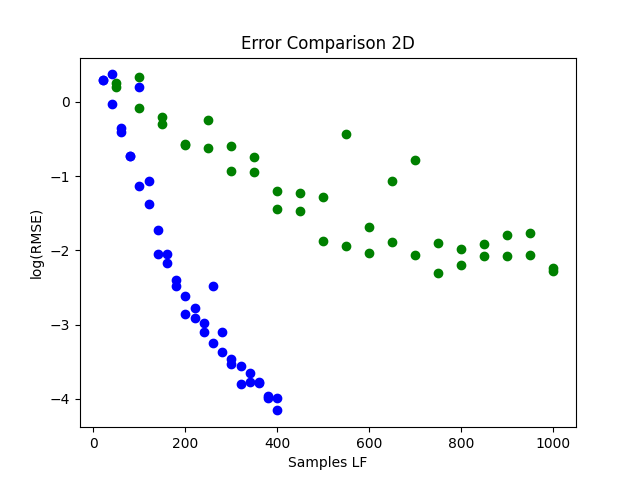

In [47]:
ax = plot_single_fidelity_data(
    points=kriging2D_points,
    output=kriging2D_error,
    label="Kriging",
    name="Error Comparison 2D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan2D_points,
    output=kan2D_error,
    label="KAN",
    name="Error Comparison 2D",
    log_output=True,
    color="green",
    ax = ax,
)
plt.show()

# 4D Comparison

In [48]:
kriging4D_points,kriging4D_error,kriging4D_traintime,kriging4D_evaltime = load_single_fidelity_csv_results('Comparisons\kriging_model_comparison_4D.csv')
kan4D_points,kan4D_error,kan4D_traintime,kan4D_evaltime = load_single_fidelity_csv_results('Comparisons\kan_model_comparison_4D.csv')

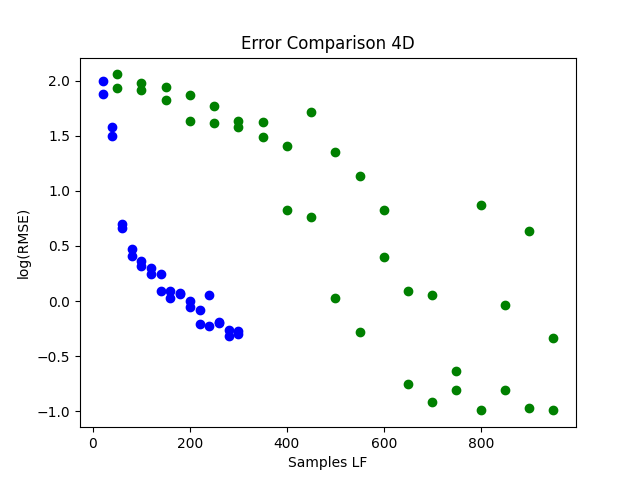

In [49]:
ax = plot_single_fidelity_data(
    points=kriging4D_points,
    output=kriging4D_error,
    label="Kriging",
    name="Error Comparison 4D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan4D_points,
    output=kan4D_error,
    label="KAN",
    name="Error Comparison 4D",
    log_output=True,
    color="green",
    ax = ax,
)
plt.show()

# 6D Comparison

In [50]:
kriging6D_points,kriging6D_error,kriging6D_traintime,kriging6D_evaltime = load_single_fidelity_csv_results('Comparisons\kriging_model_comparison_6D.csv')
kan6D_points,kan6D_error,kan6D_traintime,kan6D_evaltime = load_single_fidelity_csv_results('Comparisons\kan_model_comparison_6D.csv')

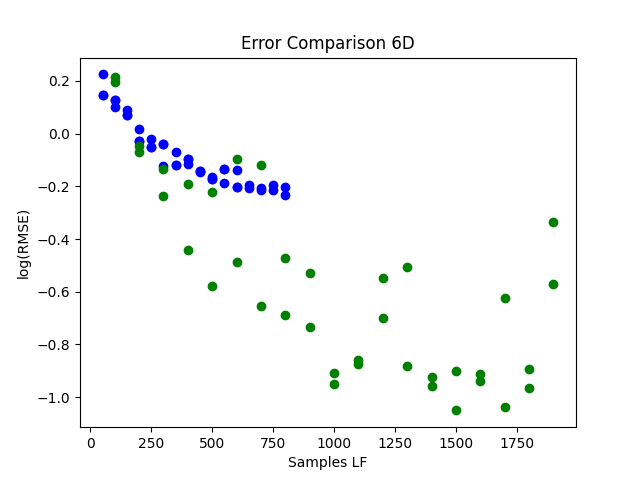

In [51]:
ax = plot_single_fidelity_data(
    points=kriging6D_points,
    output=kriging6D_error,
    label="Kriging",
    name="Error Comparison 6D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan6D_points,
    output=kan6D_error,
    label="KAN",
    name="Error Comparison 6D",
    log_output=True,
    color="green",
    ax = ax,
)
plt.show()

# 8D Comparison

In [52]:
kriging8D_points,kriging8D_error,kriging8D_traintime,kriging8D_evaltime = load_single_fidelity_csv_results('Comparisons\kriging_model_comparison_8D.csv')
kan8D_points,kan8D_error,kan8D_traintime,kan8D_evaltime = load_single_fidelity_csv_results('Comparisons\kan_model_comparison_8D.csv')

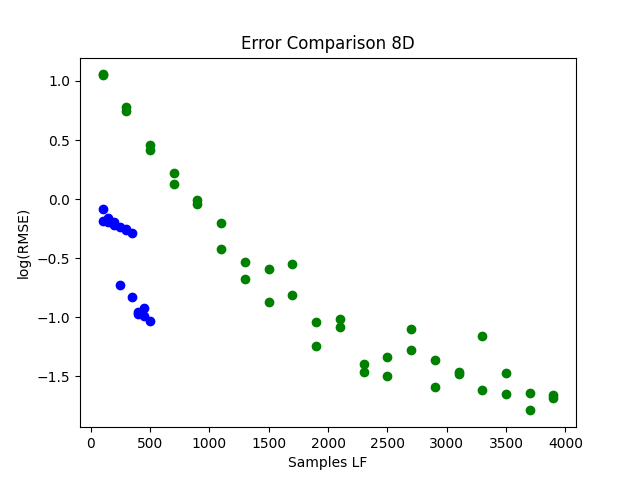

In [53]:
ax = plot_single_fidelity_data(
    points=kriging8D_points,
    output=kriging8D_error,
    label="Kriging",
    name="Error Comparison 8D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan8D_points,
    output=kan8D_error,
    label="KAN",
    name="Error Comparison 8D",
    log_output=True,
    color="green",
    ax = ax,
)
plt.show()

# 10D Comparison

In [54]:
kriging10D_points,kriging10D_error,kriging10D_traintime,kriging10D_evaltime = load_single_fidelity_csv_results('Comparisons\kriging_model_comparison_10D.csv')
kan10D_points,kan10D_error,kan10D_traintime,kan10D_evaltime = load_single_fidelity_csv_results('Comparisons\kan_model_comparison_10D.csv')

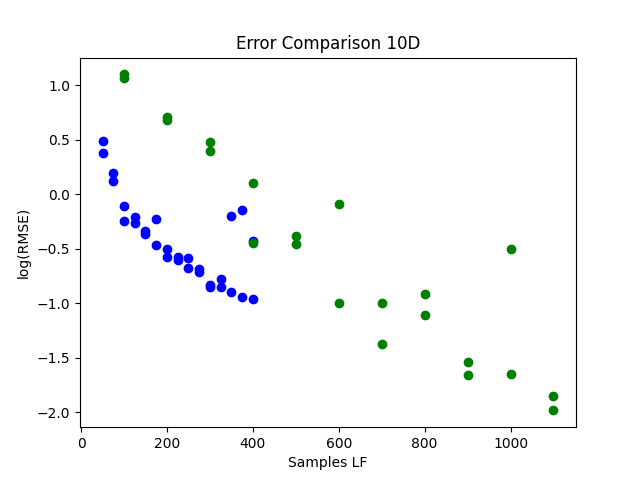

In [55]:
ax = plot_single_fidelity_data(
    points=kriging10D_points,
    output=kriging10D_error,
    label="Kriging",
    name="Error Comparison 10D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan10D_points,
    output=kan10D_error,
    label="KAN",
    name="Error Comparison 10D",
    log_output=True,
    color="green",
    ax = ax,
)
plt.show()

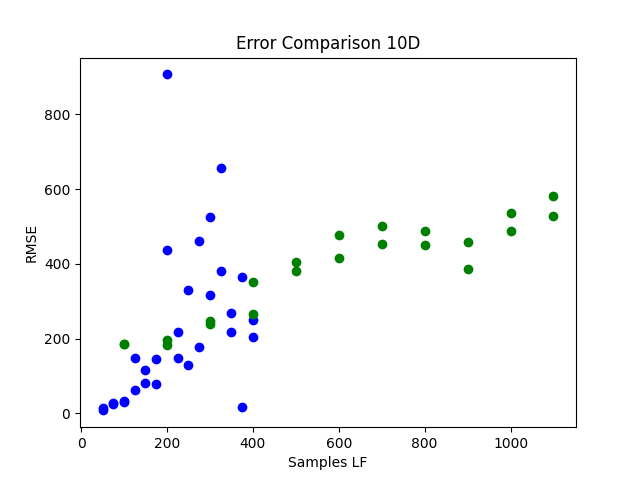

In [36]:
ax = plot_single_fidelity_data(
    points=kriging10D_points,
    output=kriging10D_traintime,
    label="Kriging",
    name="Error Comparison 10D",
    log_output=False,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan10D_points,
    output=kan10D_traintime,
    label="KAN",
    name="Error Comparison 10D",
    log_output=False,
    color="green",
    ax = ax,
)
plt.show()

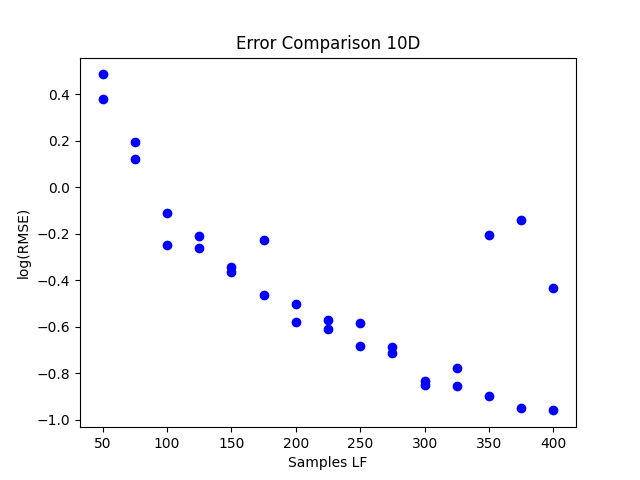

In [35]:
ax = plot_single_fidelity_data(
    points=kriging10D_points,
    output=kriging10D_error,
    label="Kriging",
    name="Error Comparison 10D",
    log_output=True,
    color="blue",
)

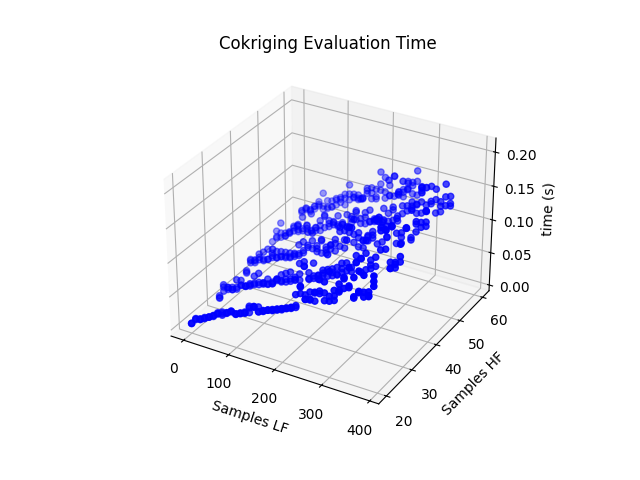

In [ ]:
ax = plot_cokriging_data(
    points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_evaluation_time, label="time (s)",name="Cokriging Evaluation Time", color="blue"
)
plt.show()

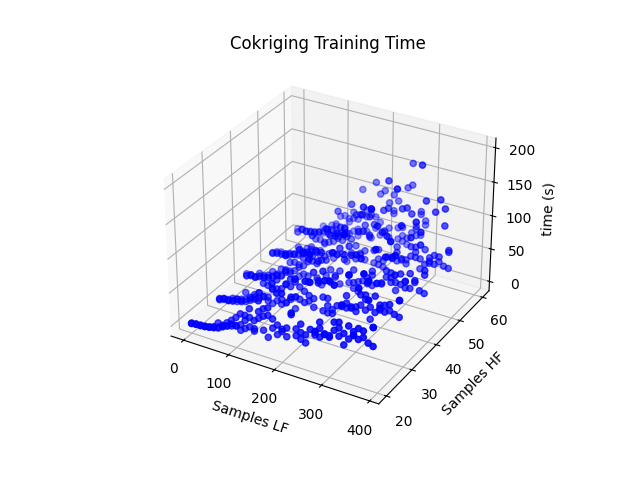

In [ ]:
ax = plot_cokriging_data(
    points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_train_time, label="time (s)",name="Cokriging Training Time", color="blue"
)
plt.show()

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


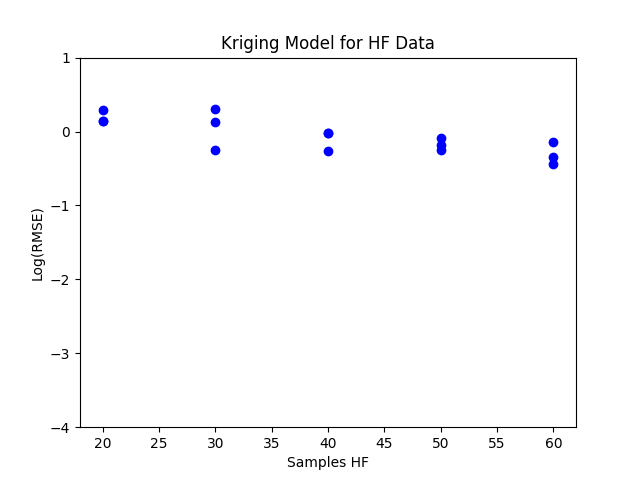

In [ ]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=0, label="Log(RMSE)",name="Kriging Model for HF Data",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


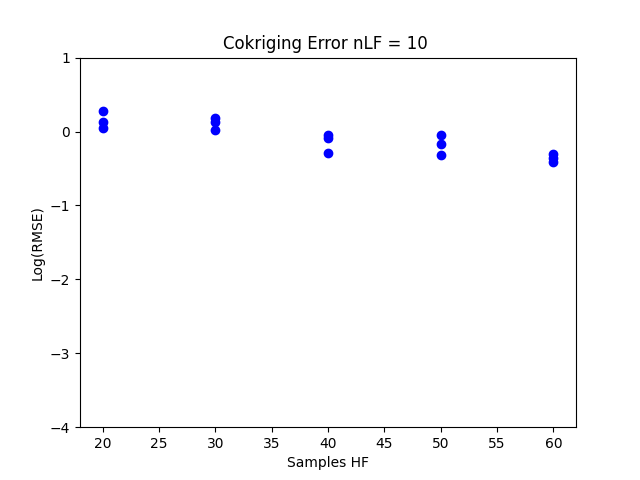

In [ ]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=10, label="Log(RMSE)",name="Cokriging Error nLF = 10 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


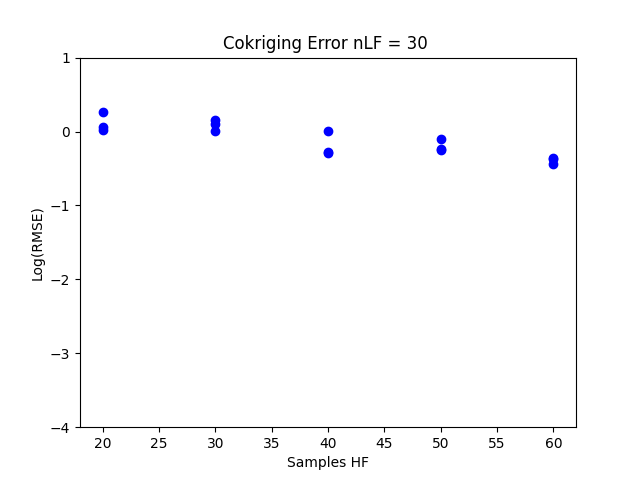

In [ ]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=30, label="Log(RMSE)",name="Cokriging Error nLF = 30 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60]


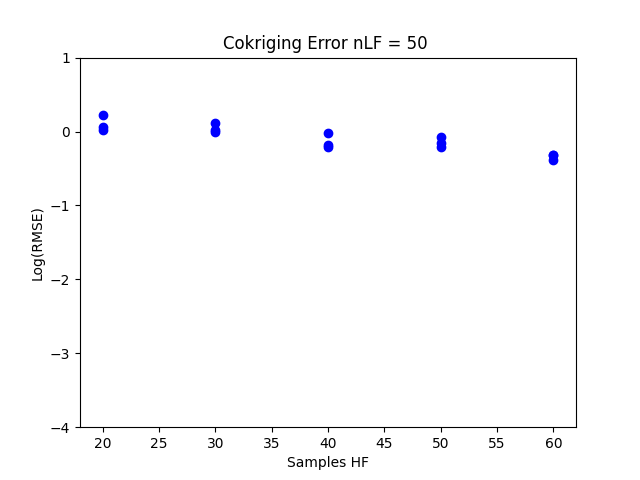

In [ ]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=50, label="Log(RMSE)",name="Cokriging Error nLF = 50 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)

[]


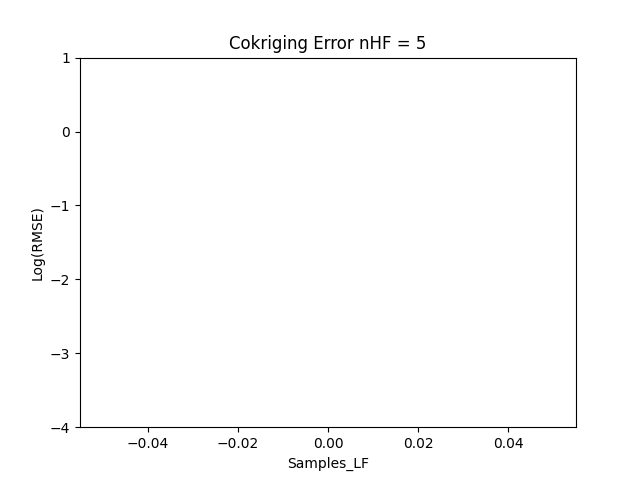

In [ ]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=5,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 5",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)

[]


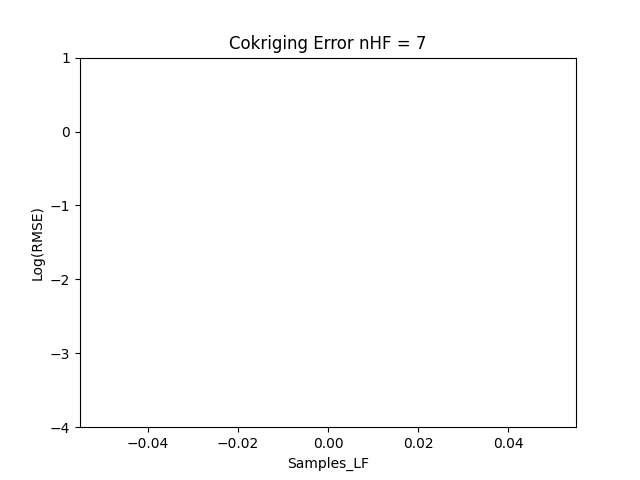

In [ ]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=7,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 7",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)

[]


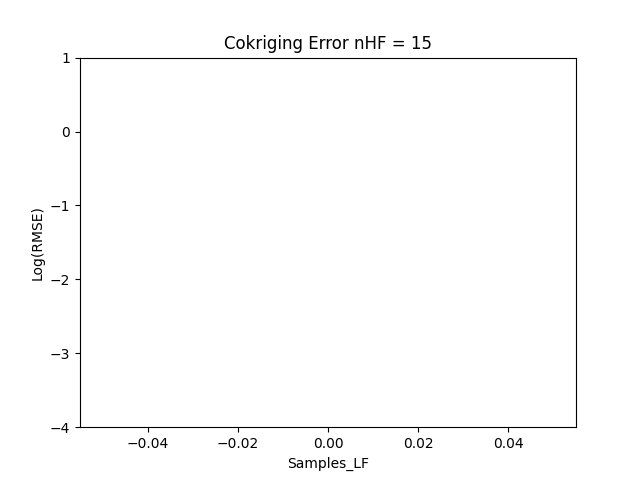

In [ ]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=15,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 15",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)

[0, 0, 0, 10, 10, 10, 20, 20, 20, 30, 30, 30, 40, 40, 40, 50, 50, 50, 60, 60, 60, 70, 70, 70, 80, 80, 80, 90, 90, 90, 100, 100, 100, 110, 110, 110, 120, 120, 120, 130, 130, 130, 140, 140, 140, 150, 150, 150, 160, 160, 160, 170, 170, 170, 180, 180, 180, 190, 190, 190, 200, 200, 200, 210, 210, 210, 220, 220, 220, 230, 230, 230, 240, 240, 240, 250, 250, 250, 260, 260, 260, 270, 270, 270, 280, 280, 280, 290, 290, 290, 300, 300, 300, 310, 310, 310, 320, 320, 320, 330, 330, 330, 340, 340, 340, 350, 350, 350, 360, 360, 360, 370, 370, 370, 380, 380, 380, 390, 390, 390]


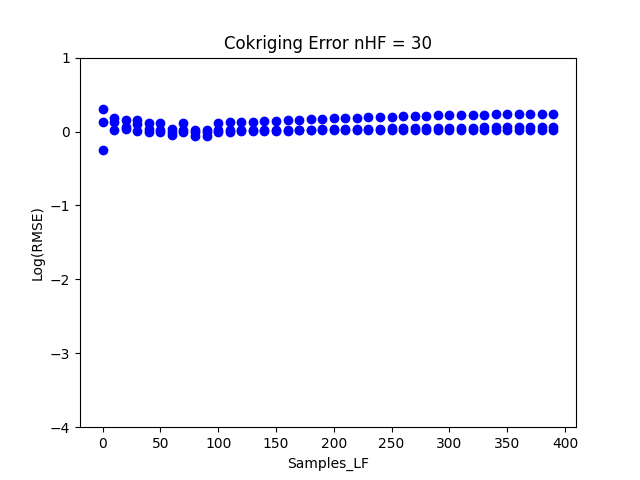

In [ ]:
ax = plot_cokriging_data_slice(
    points_lf=loaded_lf,
    points_hf=loaded_hf,
    output=loaded_error,
    fix_lf=False,
    fix_value=30,
    label="Log(RMSE)",
    name="Cokriging Error nHF = 30",
    log_output=True,
    color="blue",
)
ax.set_ybound(-4.0, 1.0)
plt.show(ax)